# Comparative Analysis of BFS, Bidirectional BFS and A* Search on the SNAP Facebook Graph
**ICE 4107 Artificial Intelligence — Project notebook (v2)**

What changed from v1:
1. **Improved A\*** added as a fourth algorithm (deeper-node tie-breaking + one target lookup per query). The original A\* is kept unchanged so both can be compared (ablation).
2. **Repeated timing**: every query is timed `REPEATS` times and the median is used.
3. **Memory usage** per query measured with `tracemalloc`, plus the size of the landmark tables.
4. **Correctness table** is now fully computed (no hard-coded zeros).
5. New tables: theoretical properties (completeness, optimality, time/space complexity), effort by path length, heuristic quality.
6. New figures: effort vs. path length, explored-nodes visualization (search process), BFS search tree.

In [1]:
# ==============================================================================
# CELL 1: Imports and Environment Setup
# ==============================================================================
import os
import sys
import gzip
import time
import math
import random
import heapq
import platform
import statistics
import tracemalloc
from collections import deque, defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import networkx as nx  # used ONLY to compute a 2-D layout for drawing figures

# Set random seed for complete experimental reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Each query is timed REPEATS times; the median time is reported
REPEATS = 5

# Output directory for saving all CSVs, plots, and figures
OUTPUT_DIR = "snap_facebook_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Python Version : {platform.python_version()}")
print(f"Operating Sys  : {platform.system()} {platform.release()}")
print(f"Output Folder  : ./{OUTPUT_DIR}/")

Python Version : 3.13.16
Operating Sys  : Linux 6.18.44-fc-v139
Output Folder  : ./snap_facebook_results/


In [2]:
# ==============================================================================
# CELL 2: Dataset Acquisition and Loading
# ==============================================================================
# The Stanford SNAP Facebook dataset contains ego-networks merged into an
# unweighted, undirected graph of 4,039 nodes and 88,234 edges.
DATASET_URL = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
LOCAL_GZ_FILE = "facebook_combined.txt.gz"
LOCAL_TXT_FILE = "facebook_combined.txt"

# Download the file automatically if it is not present in the workspace
if not os.path.exists(LOCAL_GZ_FILE) and not os.path.exists(LOCAL_TXT_FILE):
    print(f"Downloading {LOCAL_GZ_FILE} from Stanford SNAP...")
    !wget -q --show-progress {DATASET_URL} -O {LOCAL_GZ_FILE}
else:
    print("Dataset file located locally.")

def load_facebook_graph(file_path):
    """
    Loads the SNAP Facebook graph into an undirected adjacency list.
    Supports both .gz compressed files and raw .txt files.
    Eliminates self-loops and duplicate edges while indexing all nodes.
    """
    adj = defaultdict(set)
    edge_count_raw = 0

    is_gz = file_path.endswith(".gz")
    open_fn = gzip.open if is_gz else open
    mode = "rt" if is_gz else "r"

    with open_fn(file_path, mode, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    u, v = int(parts[0]), int(parts[1])
                except ValueError:
                    continue
                edge_count_raw += 1
                if u != v:  # Filter out self-loops
                    adj[u].add(v)
                    adj[v].add(u)

    # Convert sets to sorted lists for deterministic neighbor iteration
    graph = {node: sorted(list(neighbors)) for node, neighbors in adj.items()}
    return graph, edge_count_raw

dataset_target = LOCAL_GZ_FILE if os.path.exists(LOCAL_GZ_FILE) else LOCAL_TXT_FILE
t0_load = time.perf_counter()
graph, raw_edge_lines = load_facebook_graph(dataset_target)
t_load = time.perf_counter() - t0_load

num_nodes = len(graph)
num_edges = sum(len(neighs) for neighs in graph.values()) // 2

print(f"Dataset loaded in : {t_load:.4f} seconds")
print(f"Total Unique Nodes: {num_nodes:,}")
print(f"Total Undir Edges : {num_edges:,} (Raw input lines: {raw_edge_lines:,})")

Dataset file located locally.


Dataset loaded in : 0.2619 seconds
Total Unique Nodes: 4,039
Total Undir Edges : 88,234 (Raw input lines: 88,234)


In [3]:
# ==============================================================================
# CELL 3: Graph Topological Statistics (Table A)
# ==============================================================================
def compute_graph_metrics(adj_graph):
    """
    Computes rigorous graph topology statistics from the adjacency list.
    Calculates exact connected components, degrees, and sampled shortest paths.
    """
    V = len(adj_graph)
    degrees = [len(adj_graph[n]) for n in adj_graph]
    min_deg = min(degrees)
    max_deg = max(degrees)
    avg_deg = sum(degrees) / V
    E = sum(degrees) // 2

    # Graph Density: 2*E / (V*(V-1))
    density = (2.0 * E) / (V * (V - 1)) if V > 1 else 0.0

    # Connected Components via BFS Traversal
    visited = set()
    components = []
    isolated_nodes = 0

    for n in adj_graph:
        if len(adj_graph[n]) == 0:
            isolated_nodes += 1
        if n not in visited:
            comp = []
            queue = deque([n])
            visited.add(n)
            while queue:
                curr = queue.popleft()
                comp.append(curr)
                for neighbor in adj_graph[curr]:
                    if neighbor not in visited:
                        visited.add(neighbor)
                        queue.append(neighbor)
            components.append(comp)

    num_components = len(components)
    giant_comp_size = max(len(c) for c in components)

    # Exact APSP on 4,039 nodes is O(V*(V+E)) ~ 3.6e8 operations.
    # To maintain efficiency and accuracy, we use a reproducible sample of 100 nodes.
    sample_nodes = random.sample(sorted(list(adj_graph.keys())), 100)
    sample_spls = []
    sample_max_spl = 0

    for src in sample_nodes:
        dist = {src: 0}
        q = deque([src])
        while q:
            u = q.popleft()
            d_u = dist[u]
            for v in adj_graph[u]:
                if v not in dist:
                    dist[v] = d_u + 1
                    q.append(v)
                    sample_spls.append(d_u + 1)
                    if d_u + 1 > sample_max_spl:
                        sample_max_spl = d_u + 1

    avg_spl_est = sum(sample_spls) / len(sample_spls) if sample_spls else 0.0

    stats = {
        "Metric": [
            "Total Nodes (|V|)",
            "Total Undirected Edges (|E|)",
            "Average Node Degree",
            "Minimum Degree",
            "Maximum Degree",
            "Isolated Nodes",
            "Connected Components",
            "Giant Component Coverage",
            "Graph Density",
            "Average Path Length (Sampled 100-node BFS)",
            "Estimated Diameter (Sampled Max SPL)"
        ],
        "Value": [
            f"{V:,}",
            f"{E:,}",
            f"{avg_deg:.2f}",
            f"{min_deg}",
            f"{max_deg}",
            f"{isolated_nodes}",
            f"{num_components}",
            f"{giant_comp_size / V * 100:.2f}%",
            f"{density:.6f}",
            f"{avg_spl_est:.4f}",
            f"{sample_max_spl}"
        ]
    }
    return pd.DataFrame(stats)

df_table_a = compute_graph_metrics(graph)
df_table_a.to_csv(os.path.join(OUTPUT_DIR, "dataset_statistics.csv"), index=False)
print("=== Table A: Dataset Topological Statistics ===")
print(df_table_a.to_string(index=False))

=== Table A: Dataset Topological Statistics ===
                                    Metric    Value
                         Total Nodes (|V|)    4,039
              Total Undirected Edges (|E|)   88,234
                       Average Node Degree    43.69
                            Minimum Degree        1
                            Maximum Degree     1045
                            Isolated Nodes        0
                      Connected Components        1
                  Giant Component Coverage  100.00%
                             Graph Density 0.010820
Average Path Length (Sampled 100-node BFS)   3.6374
      Estimated Diameter (Sampled Max SPL)        8


### Search algorithms
Each search function takes an optional `trace` list. When a list is passed, every expanded node is appended to it as `(node, side)`. This is used only for the search-process figure; during benchmarking `trace` is `None`, so all algorithms run the same code path as before.

In [4]:
# ==============================================================================
# CELL 4: Breadth-First Search (BFS) Implementation
# ==============================================================================
def bfs_shortest_path(adj_graph, source, target, trace=None):
    """
    Finds the shortest unweighted path using Breadth-First Search.

    Node Expansion Definition:
      A node is counted as expanded when it is popped from the front of the queue
      and its outgoing adjacency list is processed.

    Returns:
      path (list), path_len (int), nodes_expanded (int), elapsed_time (float), is_valid (bool)
    """
    t_start = time.perf_counter()

    # Edge case: Source or target not in graph
    if source not in adj_graph or target not in adj_graph:
        return [], -1, 0, time.perf_counter() - t_start, False

    # Edge case: Source is Target
    if source == target:
        return [source], 0, 0, time.perf_counter() - t_start, True

    queue = deque([source])
    visited = {source}
    parent = {source: None}
    nodes_expanded = 0
    target_found = False

    while queue:
        curr = queue.popleft()
        nodes_expanded += 1
        if trace is not None:
            trace.append((curr, "F"))

        if curr == target:
            target_found = True
            break

        for neighbor in adj_graph[curr]:
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = curr
                queue.append(neighbor)

    if not target_found:
        elapsed = time.perf_counter() - t_start
        return [], -1, nodes_expanded, elapsed, False

    # Path Reconstruction (target back to source)
    path = []
    curr = target
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()

    elapsed = time.perf_counter() - t_start
    path_len = len(path) - 1
    return path, path_len, nodes_expanded, elapsed, True

In [5]:
# ==============================================================================
# CELL 5: Bidirectional Breadth-First Search Implementation
# ==============================================================================
def bidirectional_bfs_shortest_path(adj_graph, source, target, trace=None):
    """
    Finds the shortest unweighted path between source and target using
    Bidirectional BFS with balanced level-by-level frontier expansion.

    Shortest Path Guarantee:
      The search tracks the exact distance from both source and target.
      When frontiers meet, the algorithm explores remaining candidates in the
      current active frontier to guarantee that the absolute minimum (d_F + d_B)
      path is detected across all possible collision bridges.

    Node Expansion Definition:
      A node is counted as expanded when popped from whichever active frontier
      is being processed.
    """
    t_start = time.perf_counter()

    if source not in adj_graph or target not in adj_graph:
        return [], -1, 0, time.perf_counter() - t_start, False

    if source == target:
        return [source], 0, 0, time.perf_counter() - t_start, True

    # Forward search structures
    frontier_f = deque([source])
    visited_f = {source: 0}
    parent_f = {source: None}

    # Backward search structures
    frontier_b = deque([target])
    visited_b = {target: 0}
    parent_b = {target: None}

    nodes_expanded = 0
    best_len = float("inf")
    meeting_node = None

    while frontier_f and frontier_b:
        # Termination condition: if the minimum possible bridge cost exceeds best_len, stop
        curr_min_possible = visited_f[frontier_f[0]] + visited_b[frontier_b[0]]
        if curr_min_possible >= best_len:
            break

        # Always expand the smaller frontier to minimize branching surface
        if len(frontier_f) <= len(frontier_b):
            curr = frontier_f.popleft()
            nodes_expanded += 1
            if trace is not None:
                trace.append((curr, "F"))
            curr_dist = visited_f[curr]

            for neighbor in adj_graph[curr]:
                if neighbor not in visited_f:
                    visited_f[neighbor] = curr_dist + 1
                    parent_f[neighbor] = curr
                    frontier_f.append(neighbor)

                # Check collision with backward frontier
                if neighbor in visited_b:
                    total_d = visited_f[curr] + 1 + visited_b[neighbor]
                    if total_d < best_len:
                        best_len = total_d
                        meeting_node = (curr, neighbor)
        else:
            curr = frontier_b.popleft()
            nodes_expanded += 1
            if trace is not None:
                trace.append((curr, "B"))
            curr_dist = visited_b[curr]

            for neighbor in adj_graph[curr]:
                if neighbor not in visited_b:
                    visited_b[neighbor] = curr_dist + 1
                    parent_b[neighbor] = curr
                    frontier_b.append(neighbor)

                # Check collision with forward frontier
                if neighbor in visited_f:
                    total_d = visited_b[curr] + 1 + visited_f[neighbor]
                    if total_d < best_len:
                        best_len = total_d
                        meeting_node = (neighbor, curr)

    if meeting_node is None:
        elapsed = time.perf_counter() - t_start
        return [], -1, nodes_expanded, elapsed, False

    u_f, v_b = meeting_node
    # Reconstruct forward segment (source -> u_f)
    path_f = []
    curr = u_f
    while curr is not None:
        path_f.append(curr)
        curr = parent_f[curr]
    path_f.reverse()

    # Reconstruct backward segment (v_b -> target)
    path_b = []
    curr = v_b
    while curr is not None:
        path_b.append(curr)
        curr = parent_b[curr]

    full_path = path_f + path_b if u_f != v_b else path_f + path_b[1:]
    elapsed = time.perf_counter() - t_start
    path_len = len(full_path) - 1
    return full_path, path_len, nodes_expanded, elapsed, True

In [6]:
# ==============================================================================
# CELL 6: Landmark Selection, Preprocessing, and A* Implementation
# ==============================================================================
def precompute_landmark_distances(adj_graph, num_landmarks=16, seed=42):
    """
    Selects landmarks using a max-coverage pseudo-farthest node strategy.
    Runs an exhaustive unweighted BFS from each selected landmark to all nodes.

    Heuristic Admissibility & Consistency:
      By the triangle inequality in metric spaces:
        d(n, t) >= |d(L, t) - d(L, n)|
      Taking the maximum over any set of landmarks L maintains:
        1. Admissibility: h(n) <= d(n, t) for all n
        2. Consistency  : h(n) <= c(n, v) + h(v) = 1 + h(v)
    """
    t0_pre = time.perf_counter()
    rng = random.Random(seed)
    nodes = sorted(list(adj_graph.keys()))

    landmarks = []
    first_node = rng.choice(nodes)
    landmarks.append(first_node)

    # Compute distances from first landmark to pick subsequent farthest landmarks
    def bfs_all_dists(start_node):
        dist_map = {start_node: 0}
        q = deque([start_node])
        while q:
            u = q.popleft()
            d_u = dist_map[u]
            for v in adj_graph[u]:
                if v not in dist_map:
                    dist_map[v] = d_u + 1
                    q.append(v)
        return dist_map

    landmark_distances = {}
    landmark_distances[first_node] = bfs_all_dists(first_node)

    for _ in range(1, num_landmarks):
        best_candidate = None
        max_min_dist = -1
        # Sample candidates to keep landmark selection scalable
        candidates = rng.sample(nodes, min(200, len(nodes)))
        for c in candidates:
            if c in landmark_distances:
                continue
            min_dist_to_existing = min(landmark_distances[lm].get(c, float("inf")) for lm in landmarks)
            if min_dist_to_existing > max_min_dist:
                max_min_dist = min_dist_to_existing
                best_candidate = c
        if best_candidate is None:
            best_candidate = rng.choice(nodes)
        landmarks.append(best_candidate)
        landmark_distances[best_candidate] = bfs_all_dists(best_candidate)

    total_precompute_time = time.perf_counter() - t0_pre
    return landmarks, landmark_distances, total_precompute_time

print("Precomputing landmark distances (k=16)...")
LANDMARK_COUNT = 16
landmarks, landmark_dists, landmark_precompute_time = precompute_landmark_distances(
    graph, num_landmarks=LANDMARK_COUNT, seed=RANDOM_SEED
)
print(f"Precomputed {len(landmarks)} landmarks in {landmark_precompute_time:.4f} seconds.")

def a_star_shortest_path(adj_graph, source, target, landmark_dict, trace=None):
    """
    Finds the shortest path using A* Search guided by the ALT landmark heuristic.

    Node Expansion Definition:
      A node is counted as expanded when popped from the priority queue
      with a g_score matching its recorded optimal g_score (i.e. stale entries
      popped from heapq are discarded and NOT counted as valid node expansions).
    """
    t_start = time.perf_counter()

    if source not in adj_graph or target not in adj_graph:
        return [], -1, 0, time.perf_counter() - t_start, False

    if source == target:
        return [source], 0, 0, time.perf_counter() - t_start, True

    # Landmark differential heuristic function
    def heuristic(u):
        h_val = 0
        for lm, d_map in landmark_dict.items():
            if u in d_map and target in d_map:
                h_val = max(h_val, abs(d_map[u] - d_map[target]))
        return h_val

    # Priority queue stores tuples: (f_score, g_score, node)
    counter = 0  # Tie-breaker
    h_src = heuristic(source)
    open_heap = [(h_src, 0, counter, source)]
    g_score = {source: 0}
    parent = {source: None}
    closed_set = set()
    nodes_expanded = 0
    target_found = False

    while open_heap:
        f, g, _, curr = heapq.heappop(open_heap)

        # Skip stale priority queue duplicates
        if curr in closed_set or g > g_score.get(curr, float("inf")):
            continue

        closed_set.add(curr)
        nodes_expanded += 1
        if trace is not None:
            trace.append((curr, "F"))

        if curr == target:
            target_found = True
            break

        for neighbor in adj_graph[curr]:
            tentative_g = g + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                g_score[neighbor] = tentative_g
                parent[neighbor] = curr
                counter += 1
                f_neighbor = tentative_g + heuristic(neighbor)
                heapq.heappush(open_heap, (f_neighbor, tentative_g, counter, neighbor))

    if not target_found:
        elapsed = time.perf_counter() - t_start
        return [], -1, nodes_expanded, elapsed, False

    # Path Reconstruction
    path = []
    curr = target
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()

    elapsed = time.perf_counter() - t_start
    path_len = len(path) - 1
    return path, path_len, nodes_expanded, elapsed, True

Precomputing landmark distances (k=16)...


Precomputed 16 landmarks in 0.3107 seconds.


### Improved A\* (ablation)
The original A\* pushes `(f, g, counter, node)` onto the heap. When two entries have the **same f**, Python compares the next field, so the entry with the **smaller g** (closer to the source) is popped first.

On this graph the landmark heuristic is weak (h is small), so f-ties are extremely common. Breaking ties toward small g makes A\* expand nodes near the source first, which is exactly what BFS does.

The improved version makes two changes:
1. It pushes `(f, -g, counter, node)`, so among equal f the **deeper** node (closer to the goal) is popped first. This is the standard A\* tie-breaking rule.
2. It looks up the target's landmark distances **once per query** instead of inside every `h(n)` call.

Neither change affects optimality. The heap is still ordered by f first, and h is unchanged (admissible and consistent).

In [7]:
# ==============================================================================
# CELL 6b: Improved A* (deeper-node tie-breaking + one target lookup per query)
# ==============================================================================
def a_star_improved(adj_graph, source, target, landmark_dict, trace=None):
    """
    Same ALT heuristic and same expansion-count rule as a_star_shortest_path.
    Differences:
      1. Heap entries are (f, -g, counter, node): equal-f ties pop the DEEPER node.
      2. d(L, target) is read once per query for every landmark L.
    """
    t_start = time.perf_counter()

    if source not in adj_graph or target not in adj_graph:
        return [], -1, 0, time.perf_counter() - t_start, False

    if source == target:
        return [source], 0, 0, time.perf_counter() - t_start, True

    # Precompute (distance table, d(L, target)) once for this query
    lm_pairs = [(d_map, d_map[target]) for d_map in landmark_dict.values() if target in d_map]

    def heuristic(u):
        h_val = 0
        for d_map, d_t in lm_pairs:
            d_u = d_map.get(u)
            if d_u is not None:
                diff = d_u - d_t if d_u >= d_t else d_t - d_u
                if diff > h_val:
                    h_val = diff
        return h_val

    counter = 0
    open_heap = [(heuristic(source), 0, counter, source)]   # (f, -g, tie, node)
    g_score = {source: 0}
    parent = {source: None}
    closed_set = set()
    nodes_expanded = 0
    target_found = False

    while open_heap:
        f, neg_g, _, curr = heapq.heappop(open_heap)
        g = -neg_g

        # Skip stale priority-queue duplicates (not counted as expansions)
        if curr in closed_set or g > g_score.get(curr, float("inf")):
            continue

        closed_set.add(curr)
        nodes_expanded += 1
        if trace is not None:
            trace.append((curr, "F"))

        if curr == target:
            target_found = True
            break

        for neighbor in adj_graph[curr]:
            tentative_g = g + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                g_score[neighbor] = tentative_g
                parent[neighbor] = curr
                counter += 1
                heapq.heappush(open_heap, (tentative_g + heuristic(neighbor), -tentative_g, counter, neighbor))

    if not target_found:
        return [], -1, nodes_expanded, time.perf_counter() - t_start, False

    path = []
    curr = target
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()

    elapsed = time.perf_counter() - t_start
    return path, len(path) - 1, nodes_expanded, elapsed, True

In [8]:
# ==============================================================================
# CELL 7: Correctness Validation Framework
# ==============================================================================
def validate_path_integrity(adj_graph, path, source, target):
    """
    Validates three invariants on the returned path:
    1. The path starts at source and terminates at target.
    2. Every consecutive pair (u, v) exists as an edge in the adjacency list.
    3. The path contains no unexpected cycles or undefined nodes.
    """
    if not path:
        return False, "Path is empty"
    if path[0] != source:
        return False, f"Start node mismatch: {path[0]} != {source}"
    if path[-1] != target:
        return False, f"End node mismatch: {path[-1]} != {target}"
    for i in range(len(path) - 1):
        u, v = path[i], path[i + 1]
        if v not in adj_graph.get(u, []):
            return False, f"Non-existent edge: ({u}, {v})"
    return True, "Valid"

### Benchmark
All four algorithms run on the same 200 source-target pairs (seed 42). For each query, the path and the node count come from the first run, and the time is the **median of `REPEATS` runs**. BFS is the ground truth for path length.

In [9]:
# ==============================================================================
# CELL 8: Performance Evaluation and Benchmarking Suite (4 algorithms, repeated timing)
# ==============================================================================
NUM_TEST_PAIRS = 200
all_nodes = sorted(list(graph.keys()))
rng_pairs = random.Random(RANDOM_SEED)

test_pairs = []
while len(test_pairs) < NUM_TEST_PAIRS:
    s = rng_pairs.choice(all_nodes)
    t = rng_pairs.choice(all_nodes)
    if s != t:
        test_pairs.append((s, t))

# key -> (display name, function(source, target, trace=None))
ALGORITHMS = {
    "bfs":  ("BFS",                    lambda s, t, tr=None: bfs_shortest_path(graph, s, t, tr)),
    "bi":   ("Bidirectional BFS",      lambda s, t, tr=None: bidirectional_bfs_shortest_path(graph, s, t, tr)),
    "ast":  ("A* (ALT, original)",     lambda s, t, tr=None: a_star_shortest_path(graph, s, t, landmark_dists, tr)),
    "ast2": ("A* (ALT, improved)",     lambda s, t, tr=None: a_star_improved(graph, s, t, landmark_dists, tr)),
}
ALG_KEYS = list(ALGORITHMS.keys())
ALG_NAMES = {k: v[0] for k, v in ALGORITHMS.items()}

print(f"Benchmarking {len(ALG_KEYS)} algorithms on {NUM_TEST_PAIRS} pairs, {REPEATS} timing runs each...")

raw_results = []
for idx, (src, tgt) in enumerate(test_pairs):
    row = {"pair_id": idx + 1, "source": src, "target": tgt}
    for key in ALG_KEYS:
        fn = ALGORITHMS[key][1]
        path, p_len, p_exp, p_time, found = fn(src, tgt)
        times = [p_time] + [fn(src, tgt)[3] for _ in range(REPEATS - 1)]
        valid, _ = validate_path_integrity(graph, path, src, tgt)
        row[f"{key}_path"] = path
        row[f"{key}_len"] = p_len
        row[f"{key}_exp"] = p_exp
        row[f"{key}_time_ms"] = statistics.median(times) * 1000.0
        row[f"{key}_found"] = found
        row[f"{key}_valid"] = valid
    for key in ALG_KEYS:
        row[f"{key}_mismatch"] = (key != "bfs") and (row[f"{key}_len"] != row["bfs_len"])
        row[f"{key}_ok"] = row[f"{key}_found"] and row[f"{key}_valid"] and not row[f"{key}_mismatch"]
    raw_results.append(row)

df_raw = pd.DataFrame(raw_results)
df_raw.drop(columns=[f"{k}_path" for k in ALG_KEYS]).to_csv(
    os.path.join(OUTPUT_DIR, "raw_search_experiments.csv"), index=False)
print("Benchmarking completed. Raw results saved.")

Benchmarking 4 algorithms on 200 pairs, 5 timing runs each...


Benchmarking completed. Raw results saved.


### Memory usage
`tracemalloc` records the **peak memory allocated during one query**: the queues, the visited/closed sets, the parent and distance dictionaries, and the heap. The graph itself is shared by all algorithms and is not counted. Memory is measured in a separate loop because tracemalloc slows code down, so it must not affect the timing results.

The landmark tables are a one-time structure used only by A\*. Their retained size is measured separately.

In [10]:
# ==============================================================================
# CELL 8b: Memory Usage Measurement (tracemalloc)
# ==============================================================================
def peak_memory_kb(fn, s, t):
    """Peak memory (KB) allocated while running one query."""
    tracemalloc.start()
    fn(s, t)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024.0

for key in ALG_KEYS:
    fn = ALGORITHMS[key][1]
    df_raw[f"{key}_mem_kb"] = [peak_memory_kb(fn, s, t) for s, t in test_pairs]

# Retained size of the landmark distance tables (one-time A* preprocessing structure)
tracemalloc.start()
_lm_tmp, _ld_tmp, _ = precompute_landmark_distances(graph, num_landmarks=LANDMARK_COUNT, seed=RANDOM_SEED)
landmark_table_kb = tracemalloc.get_traced_memory()[0] / 1024.0
tracemalloc.stop()
del _lm_tmp, _ld_tmp

df_raw.drop(columns=[f"{k}_path" for k in ALG_KEYS], errors="ignore").to_csv(
    os.path.join(OUTPUT_DIR, "raw_search_experiments.csv"), index=False)

for key in ALG_KEYS:
    m = df_raw[f"{key}_mem_kb"]
    print(f"{ALG_NAMES[key]:22s} peak memory per query: mean {m.mean():7.1f} KB | median {m.median():7.1f} KB | max {m.max():7.1f} KB")
print(f"Landmark tables (k={LANDMARK_COUNT}, one-time): {landmark_table_kb:,.1f} KB")

BFS                    peak memory per query: mean   318.0 KB | median   359.5 KB | max   366.7 KB
Bidirectional BFS      peak memory per query: mean   160.4 KB | median   174.5 KB | max   345.8 KB
A* (ALT, original)     peak memory per query: mean   224.1 KB | median   233.8 KB | max   543.8 KB
A* (ALT, improved)     peak memory per query: mean   178.6 KB | median   160.8 KB | max   329.0 KB
Landmark tables (k=16, one-time): 2,307.1 KB


### Results tables
- **Table B**: sample results for the first 10 pairs
- **Table C**: aggregate comparison
- **Table D**: correctness
- **Table E**: configuration
- **Table F**: theoretical properties
- **Table G**: effort by path length
- **Table H**: heuristic quality

In [11]:
# ==============================================================================
# CELL 9: Results Tables Compilation (Tables B-H)
# ==============================================================================
# --- Table B: Individual results sample (first 10 pairs) ---
rows_b = []
for r in raw_results[:10]:
    for key in ALG_KEYS:
        rows_b.append({
            "Pair ID": r["pair_id"], "Source": r["source"], "Target": r["target"],
            "Algorithm": ALG_NAMES[key],
            "Path Length": r[f"{key}_len"],
            "Nodes Expanded": r[f"{key}_exp"],
            "Time (ms)": f"{df_raw.loc[r['pair_id'] - 1, f'{key}_time_ms']:.3f}",
            "Peak Memory (KB)": f"{df_raw.loc[r['pair_id'] - 1, f'{key}_mem_kb']:.1f}",
            "Path Valid": r[f"{key}_valid"],
            "Matches BFS": not r[f"{key}_mismatch"],
        })
df_table_b = pd.DataFrame(rows_b)
df_table_b.to_csv(os.path.join(OUTPUT_DIR, "sample_path_results.csv"), index=False)

# --- Table C: Aggregate comparison ---
summary_c = []
for key in ALG_KEYS:
    is_astar = key.startswith("ast")
    summary_c.append({
        "Algorithm": ALG_NAMES[key],
        "Avg Path Length": f"{df_raw[f'{key}_len'].mean():.3f}",
        "Avg Nodes Expanded": f"{df_raw[f'{key}_exp'].mean():.1f}",
        "Avg Query Time (ms)": f"{df_raw[f'{key}_time_ms'].mean():.3f}",
        "Median Query Time (ms)": f"{df_raw[f'{key}_time_ms'].median():.3f}",
        "Std Dev Time (ms)": f"{df_raw[f'{key}_time_ms'].std():.3f}",
        "Avg Peak Memory (KB)": f"{df_raw[f'{key}_mem_kb'].mean():.1f}",
        "Correctness (%)": f"{df_raw[f'{key}_ok'].mean() * 100:.1f}%",
        "Preprocessing": (f"{landmark_precompute_time:.2f} s, {landmark_table_kb / 1024:.2f} MB (one-time, shared)"
                          if is_astar else "none"),
    })
df_table_c = pd.DataFrame(summary_c)
df_table_c.to_csv(os.path.join(OUTPUT_DIR, "algorithm_comparison.csv"), index=False)

# --- Table D: Correctness validation (all columns computed) ---
summary_d = []
for key in ALG_KEYS:
    summary_d.append({
        "Algorithm": ALG_NAMES[key],
        "Total Test Pairs": NUM_TEST_PAIRS,
        "Successful Tests": int(df_raw[f"{key}_ok"].sum()),
        "Failed Tests": int(NUM_TEST_PAIRS - df_raw[f"{key}_ok"].sum()),
        "Path Length Mismatches": "reference" if key == "bfs" else int(df_raw[f"{key}_mismatch"].sum()),
        "Invalid Edges/Paths": int((~df_raw[f"{key}_valid"]).sum()),
        "No Path Returned": int((~df_raw[f"{key}_found"]).sum()),
        "Correctness (%)": f"{df_raw[f'{key}_ok'].mean() * 100:.1f}%",
    })
df_table_d = pd.DataFrame(summary_d)
df_table_d.to_csv(os.path.join(OUTPUT_DIR, "correctness_validation.csv"), index=False)

# --- Table E: Experimental configuration ---
config_e = {
    "Configuration Parameter": [
        "Tested Source-Target Pairs", "Random Seed", "Timing Runs per Query",
        "Landmark Count (|L|)", "Landmark Selection Strategy", "Timing Function",
        "Memory Measurement", "Node Expansion Rule", "Graph Representation",
        "Edge Weight Scheme", "A* Tie-breaking (original / improved)", "Python Runtime Environment",
    ],
    "Specification / Value": [
        f"{NUM_TEST_PAIRS}", f"{RANDOM_SEED}", f"{REPEATS} (median reported)",
        f"{LANDMARK_COUNT}", "Farthest-Node Max-Coverage (Sampled)", "time.perf_counter()",
        "tracemalloc peak per query (separate run)",
        "Counted on pop from active queue/heap with valid distance",
        "Adjacency list with sorted lists", "Unweighted (Unit cost = 1.0)",
        "Smaller g first / Larger g first",
        f"Python {platform.python_version()} on {platform.system()}",
    ],
}
df_table_e = pd.DataFrame(config_e)
df_table_e.to_csv(os.path.join(OUTPUT_DIR, "experimental_configuration.csv"), index=False)

# --- Table F: Theoretical properties (b = branching factor, d = solution depth, k = landmarks) ---
df_table_f = pd.DataFrame({
    "Algorithm": ["BFS", "Bidirectional BFS", "A* (ALT)"],
    "Complete": ["Yes (finite graph)", "Yes (finite graph)", "Yes (finite graph)"],
    "Optimal": ["Yes (unit edge costs)", "Yes (with the best_len stop rule)", "Yes (h admissible and consistent)"],
    "Time Complexity": ["O(b^d), at most O(V + E)", "O(b^(d/2)), at most O(V + E)",
                        "O(b^d) worst case; preprocessing O(k(V + E))"],
    "Space Complexity": ["O(b^d), at most O(V)", "O(b^(d/2)), at most O(V)",
                         "O(b^d) per query + O(kV) landmark tables"],
})
df_table_f.to_csv(os.path.join(OUTPUT_DIR, "theoretical_properties.csv"), index=False)

# --- Table G: Effort by shortest-path length (solution depth) ---
agg = {"pair_id": "count"}
for key in ALG_KEYS:
    agg[f"{key}_exp"] = "mean"
    agg[f"{key}_time_ms"] = "mean"
    agg[f"{key}_mem_kb"] = "mean"
df_table_g = df_raw.groupby("bfs_len").agg(agg).reset_index()
df_table_g = df_table_g.rename(columns={"bfs_len": "Path Length (edges)", "pair_id": "Pairs"})
df_table_g.to_csv(os.path.join(OUTPUT_DIR, "effort_by_path_length.csv"), index=False, float_format="%.2f")

# --- Table H: Heuristic quality at the source node ---
def alt_h(u, t):
    return max(abs(d[u] - d[t]) for d in landmark_dists.values() if u in d and t in d)

h_src = np.array([alt_h(s, t) for s, t in test_pairs])
true_d = df_raw["bfs_len"].to_numpy()
ratio = h_src / true_d
df_table_h = pd.DataFrame({
    "Measure": [
        "Mean h(s) / d(s,t)", "Median h(s) / d(s,t)",
        "Pairs with h(s) = 0 (no guidance at start)", "Pairs with h(s) = d(s,t) (perfect estimate)",
        "Mean h(s) (edges)", "Mean true distance d(s,t) (edges)",
    ],
    "Value": [
        f"{ratio.mean():.3f}", f"{np.median(ratio):.3f}",
        f"{int((h_src == 0).sum())} of {NUM_TEST_PAIRS}", f"{int((h_src == true_d).sum())} of {NUM_TEST_PAIRS}",
        f"{h_src.mean():.3f}", f"{true_d.mean():.3f}",
    ],
})
df_table_h.to_csv(os.path.join(OUTPUT_DIR, "heuristic_quality.csv"), index=False)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
print("=== Table C: Aggregate Algorithm Comparison ===")
print(df_table_c.to_string(index=False))
print("\n=== Table D: Correctness Validation Summary ===")
print(df_table_d.to_string(index=False))
print("\n=== Table F: Theoretical Properties ===")
print(df_table_f.to_string(index=False))
print("\n=== Table G: Effort by Path Length ===")
print(df_table_g.round(2).to_string(index=False))
print("\n=== Table H: Heuristic Quality (ALT, k=16) ===")
print(df_table_h.to_string(index=False))

=== Table C: Aggregate Algorithm Comparison ===
         Algorithm Avg Path Length Avg Nodes Expanded Avg Query Time (ms) Median Query Time (ms) Std Dev Time (ms) Avg Peak Memory (KB) Correctness (%)                      Preprocessing
               BFS           3.665             1911.4               6.314                  5.840             4.207                318.0          100.0%                               none
 Bidirectional BFS           3.665              240.7               1.507                  0.588             2.043                160.4          100.0%                               none
A* (ALT, original)           3.665              776.1              18.457                 16.795            10.569                224.1          100.0% 0.31 s, 2.25 MB (one-time, shared)
A* (ALT, improved)           3.665              298.7               9.119                  7.725             5.982                178.6          100.0% 0.31 s, 2.25 MB (one-time, shared)

=== Table D: Cor

In [12]:
# ==============================================================================
# CELL 9b: Pairwise Comparison Statistics (for the discussion text)
# ==============================================================================
def share(mask):
    return f"{mask.sum()} of {NUM_TEST_PAIRS} ({mask.mean() * 100:.1f}%)"

lines = [
    ("Bi-BFS expands fewer nodes than BFS", df_raw.bi_exp < df_raw.bfs_exp),
    ("Bi-BFS faster than BFS", df_raw.bi_time_ms < df_raw.bfs_time_ms),
    ("A* (original) expands fewer nodes than BFS", df_raw.ast_exp < df_raw.bfs_exp),
    ("A* (original) expands fewer nodes than Bi-BFS", df_raw.ast_exp < df_raw.bi_exp),
    ("A* (original) faster than BFS", df_raw.ast_time_ms < df_raw.bfs_time_ms),
    ("A* (improved) expands fewer nodes than A* (original)", df_raw.ast2_exp < df_raw.ast_exp),
    ("A* (improved) expands fewer nodes than BFS", df_raw.ast2_exp < df_raw.bfs_exp),
    ("A* (improved) expands fewer nodes than Bi-BFS", df_raw.ast2_exp < df_raw.bi_exp),
    ("A* (improved) faster than BFS", df_raw.ast2_time_ms < df_raw.bfs_time_ms),
    ("A* (improved) faster than Bi-BFS", df_raw.ast2_time_ms < df_raw.bi_time_ms),
]
for text, mask in lines:
    print(f"{text:55s}: {share(mask)}")

reduction = 1 - df_raw.ast2_exp.mean() / df_raw.ast_exp.mean()
speedup = df_raw.ast_time_ms.mean() / df_raw.ast2_time_ms.mean()
print(f"\nImproved A* reduces average expansions by {reduction * 100:.1f}% and is {speedup:.2f}x faster than the original A*.")
for key in ALG_KEYS:
    per_node = (df_raw[f"{key}_time_ms"] / df_raw[f"{key}_exp"]).mean()
    print(f"Average time per expanded node, {ALG_NAMES[key]:22s}: {per_node:.4f} ms")

Bi-BFS expands fewer nodes than BFS                    : 200 of 200 (100.0%)
Bi-BFS faster than BFS                                 : 196 of 200 (98.0%)
A* (original) expands fewer nodes than BFS             : 189 of 200 (94.5%)
A* (original) expands fewer nodes than Bi-BFS          : 22 of 200 (11.0%)
A* (original) faster than BFS                          : 10 of 200 (5.0%)
A* (improved) expands fewer nodes than A* (original)   : 193 of 200 (96.5%)
A* (improved) expands fewer nodes than BFS             : 190 of 200 (95.0%)
A* (improved) expands fewer nodes than Bi-BFS          : 72 of 200 (36.0%)
A* (improved) faster than BFS                          : 60 of 200 (30.0%)
A* (improved) faster than Bi-BFS                       : 5 of 200 (2.5%)

Improved A* reduces average expansions by 61.5% and is 2.02x faster than the original A*.
Average time per expanded node, BFS                   : 0.0036 ms
Average time per expanded node, Bidirectional BFS     : 0.0116 ms
Average time per expande

### Performance charts

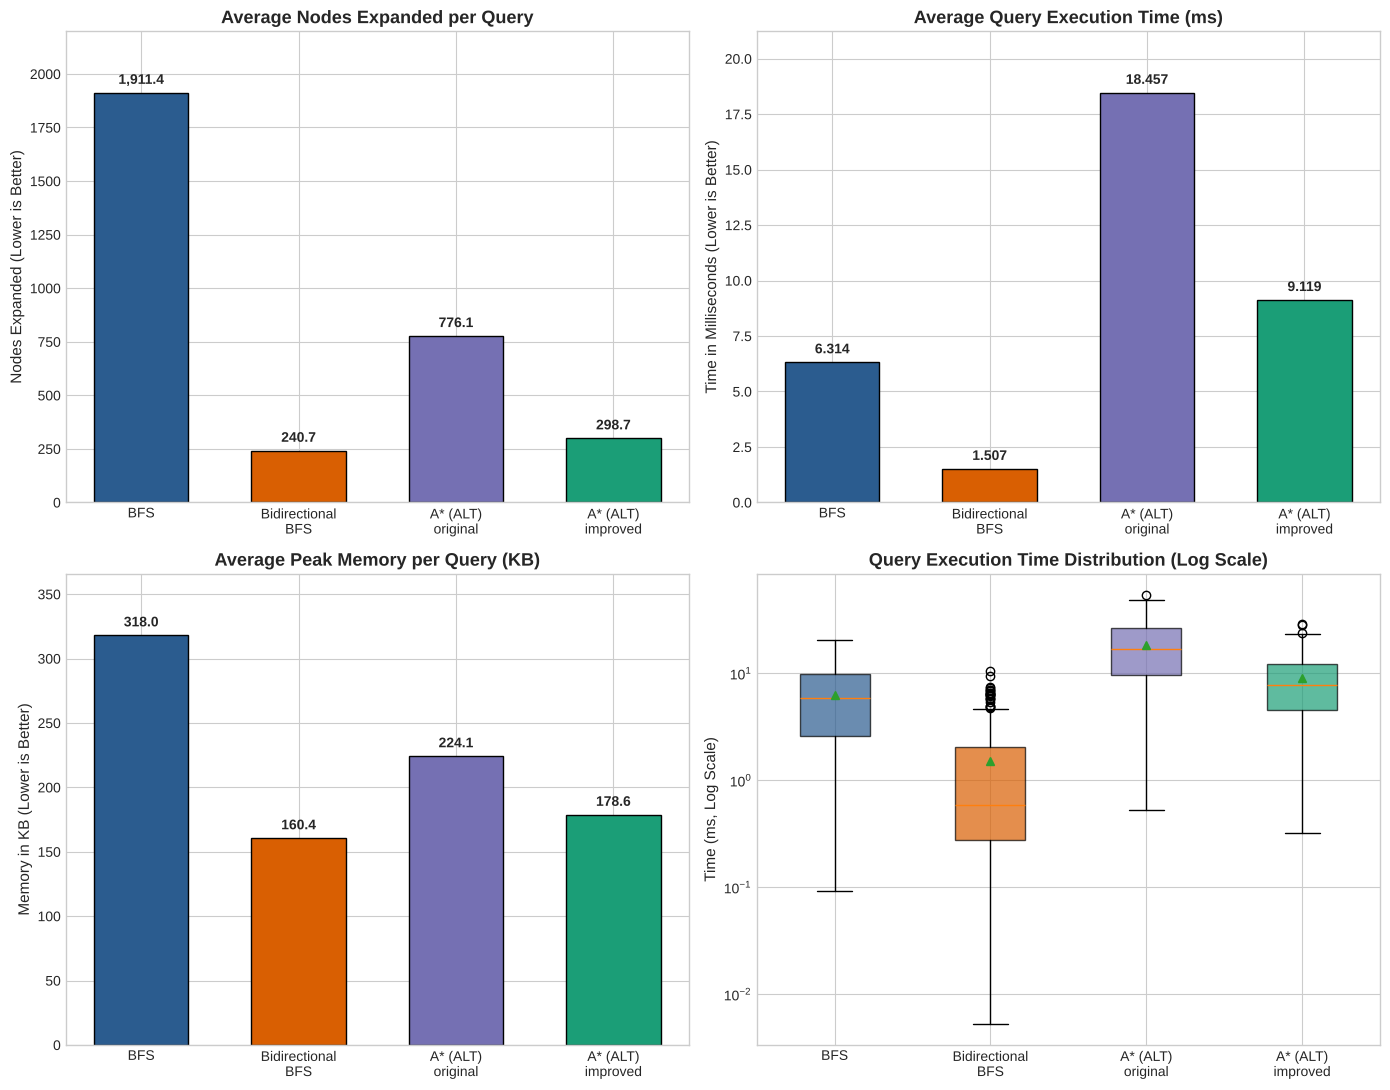

Comparative charts saved to snap_facebook_results/performance_comparison_charts.png


In [13]:
# ==============================================================================
# CELL 10: Comparative Matplotlib Visualizations
# ==============================================================================
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
palette = ["#2b5c8f", "#d95f02", "#7570b3", "#1b9e77"]
labels = ["BFS", "Bidirectional\nBFS", "A* (ALT)\noriginal", "A* (ALT)\nimproved"]

def bar_panel(ax, values, title, ylabel, fmt):
    bars = ax.bar(labels, values, color=palette, width=0.6, edgecolor="black")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, max(values) * 1.15)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + max(values) * 0.015, fmt(h),
                ha="center", va="bottom", fontsize=10, fontweight="bold")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
bar_panel(axes[0, 0], [df_raw[f"{k}_exp"].mean() for k in ALG_KEYS],
          "Average Nodes Expanded per Query", "Nodes Expanded (Lower is Better)", lambda h: f"{h:,.1f}")
bar_panel(axes[0, 1], [df_raw[f"{k}_time_ms"].mean() for k in ALG_KEYS],
          "Average Query Execution Time (ms)", "Time in Milliseconds (Lower is Better)", lambda h: f"{h:.3f}")
bar_panel(axes[1, 0], [df_raw[f"{k}_mem_kb"].mean() for k in ALG_KEYS],
          "Average Peak Memory per Query (KB)", "Memory in KB (Lower is Better)", lambda h: f"{h:,.1f}")

# Boxplot: 'labels' was renamed 'tick_labels' in Matplotlib 3.9
time_data = [df_raw[f"{k}_time_ms"] for k in ALG_KEYS]
try:
    box = axes[1, 1].boxplot(time_data, tick_labels=labels, patch_artist=True, showmeans=True)
except TypeError:
    box = axes[1, 1].boxplot(time_data, labels=labels, patch_artist=True, showmeans=True)
for patch, color in zip(box["boxes"], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Query Execution Time Distribution (Log Scale)", fontsize=13, fontweight="bold")
axes[1, 1].set_ylabel("Time (ms, Log Scale)", fontsize=11)

plt.tight_layout()
charts_path = os.path.join(OUTPUT_DIR, "performance_comparison_charts.png")
plt.savefig(charts_path, dpi=300)
plt.show()
print(f"Comparative charts saved to {charts_path}")

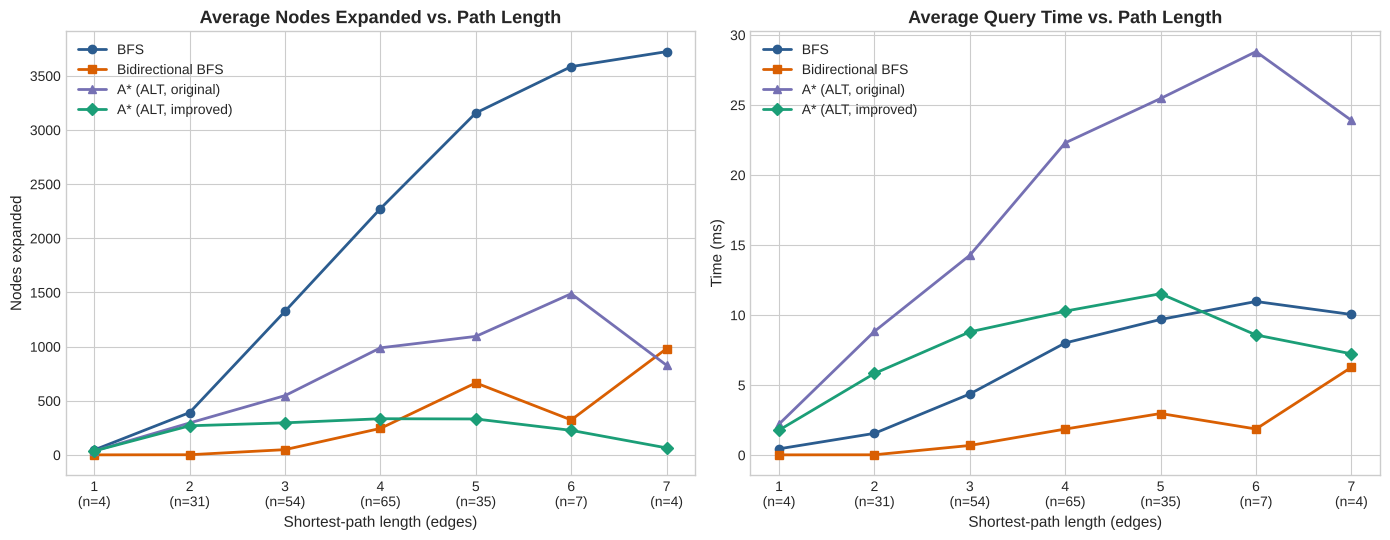

Saved to snap_facebook_results/effort_vs_path_length.png


In [14]:
# ==============================================================================
# CELL 10b: Search Effort vs. Solution Depth
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
depths = df_table_g["Path Length (edges)"]
names = [ALG_NAMES[k] for k in ALG_KEYS]
markers = ["o", "s", "^", "D"]
for key, name, color, mk in zip(ALG_KEYS, names, palette, markers):
    axes[0].plot(depths, df_table_g[f"{key}_exp"], marker=mk, color=color, lw=2, label=name)
    axes[1].plot(depths, df_table_g[f"{key}_time_ms"], marker=mk, color=color, lw=2, label=name)
axes[0].set_title("Average Nodes Expanded vs. Path Length", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Shortest-path length (edges)", fontsize=11)
axes[0].set_ylabel("Nodes expanded", fontsize=11)
axes[1].set_title("Average Query Time vs. Path Length", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Shortest-path length (edges)", fontsize=11)
axes[1].set_ylabel("Time (ms)", fontsize=11)
tick_text = [f"{d}\n(n={n})" for d, n in zip(depths, df_table_g["Pairs"])]
for ax in axes:
    ax.set_xticks(depths)
    ax.set_xticklabels(tick_text)
    ax.legend(fontsize=10)
plt.tight_layout()
depth_path = os.path.join(OUTPUT_DIR, "effort_vs_path_length.png")
plt.savefig(depth_path, dpi=300)
plt.show()
print(f"Saved to {depth_path}")

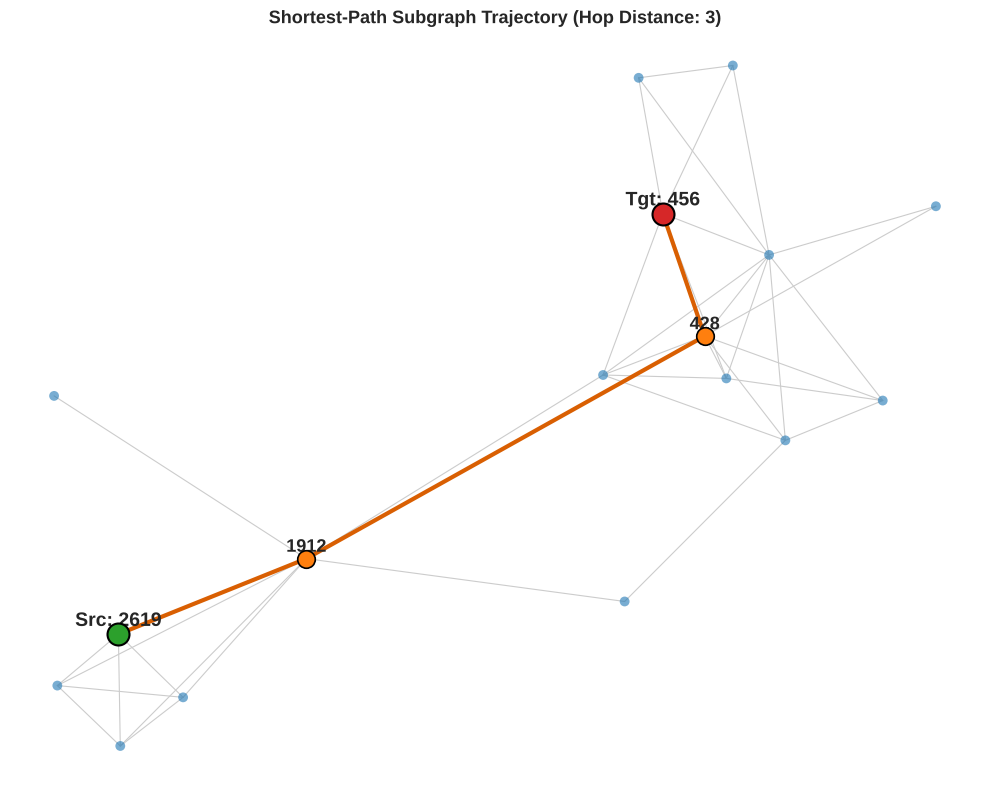

Path visualization saved to snap_facebook_results/sample_path_visualization.png


In [15]:
# ==============================================================================
# CELL 11: Sample Shortest-Path Subgraph Visualization
# ==============================================================================
def visualize_shortest_path_subgraph(adj_graph, path, output_path):
    """
    Renders an ego-centric subgraph around a sample shortest path.
    Includes the path nodes, their immediate interconnected neighbors,
    and highlights the trajectory from source to target.
    """
    if len(path) < 2:
        print("Path too short to render meaningful subgraph.")
        return

    path_nodes = set(path)
    # Extract immediate neighborhood of path nodes to illustrate graph density
    subgraph_nodes = set(path)
    for p_node in path:
        neighbors = adj_graph.get(p_node, [])
        # Sample at most 4 neighbors per path node to prevent visual crowding
        subgraph_nodes.update(neighbors[:4])

    subgraph_list = sorted(list(subgraph_nodes))
    node_idx = {n: i for i, n in enumerate(subgraph_list)}

    # Compute deterministic 2D spring layout for subgraph
    rng_pos = np.random.RandomState(42)
    pos = {n: rng_pos.uniform(-1, 1, size=2) for n in subgraph_list}

    # Simple force-directed positioning iterations
    for _ in range(40):
        disp = {n: np.zeros(2) for n in subgraph_list}
        for i, u in enumerate(subgraph_list):
            for j, v in enumerate(subgraph_list):
                if i != j:
                    delta = pos[u] - pos[v]
                    dist = max(np.linalg.norm(delta), 0.05)
                    disp[u] += (delta / dist) * (0.08 / dist)
            for neighbor in adj_graph[u]:
                if neighbor in subgraph_nodes:
                    delta = pos[neighbor] - pos[u]
                    dist = max(np.linalg.norm(delta), 0.05)
                    disp[u] += delta * 0.15
        for u in subgraph_list:
            pos[u] += np.clip(disp[u], -0.2, 0.2)

    plt.figure(figsize=(10, 8))

    # 1. Draw non-path background edges
    for u in subgraph_nodes:
        for v in adj_graph[u]:
            if v in subgraph_nodes and u < v:
                if not (u in path_nodes and v in path_nodes and abs(path.index(u) - path.index(v)) == 1):
                    plt.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
                             color="#cccccc", lw=0.8, zorder=1)

    # 2. Draw highlighted shortest path edges
    for i in range(len(path) - 1):
        u, v = path[i], path[i + 1]
        plt.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
                 color="#d95f02", lw=3.0, zorder=3)

    # 3. Draw nodes
    for n in subgraph_nodes:
        if n == path[0]:
            plt.scatter(pos[n][0], pos[n][1], s=250, c="#2ca02c", edgecolors="black", lw=1.5, zorder=4, label="Source")
            plt.text(pos[n][0], pos[n][1] + 0.06, f"Src: {n}", fontsize=14, fontweight="bold", ha="center")
        elif n == path[-1]:
            plt.scatter(pos[n][0], pos[n][1], s=250, c="#d62728", edgecolors="black", lw=1.5, zorder=4, label="Target")
            plt.text(pos[n][0], pos[n][1] + 0.06, f"Tgt: {n}", fontsize=14, fontweight="bold", ha="center")
        elif n in path_nodes:
            plt.scatter(pos[n][0], pos[n][1], s=160, c="#ff7f0e", edgecolors="black", lw=1.2, zorder=4)
            plt.text(pos[n][0], pos[n][1] + 0.05, f"{n}", fontsize=13, fontweight="bold", ha="center")
        else:
            plt.scatter(pos[n][0], pos[n][1], s=50, c="#1f77b4", alpha=0.6, edgecolors="none", zorder=2)

    plt.title(f"Shortest-Path Subgraph Trajectory (Hop Distance: {len(path)-1})", fontsize=13, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    print(f"Path visualization saved to {output_path}")

# Pick a sample path from the benchmarking suite with length >= 3
sample_pair = next(r for r in raw_results if r["bfs_len"] >= 3)
p_sample, _, _, _, _ = bfs_shortest_path(graph, sample_pair["source"], sample_pair["target"])
visualize_shortest_path_subgraph(graph, p_sample, os.path.join(OUTPUT_DIR, "sample_path_visualization.png"))

### Visualization of the search process
Every node of the graph is drawn in light grey. The coloured nodes are the ones each algorithm **expanded** for the same source-target pair. For Bidirectional BFS, blue is the forward search and orange is the backward search. The red line is the shortest path found.

Computing the 2-D layout of all 4,039 nodes takes about one minute. It is computed once and reused for every panel.

Computing full-graph layout (about 1 minute)...


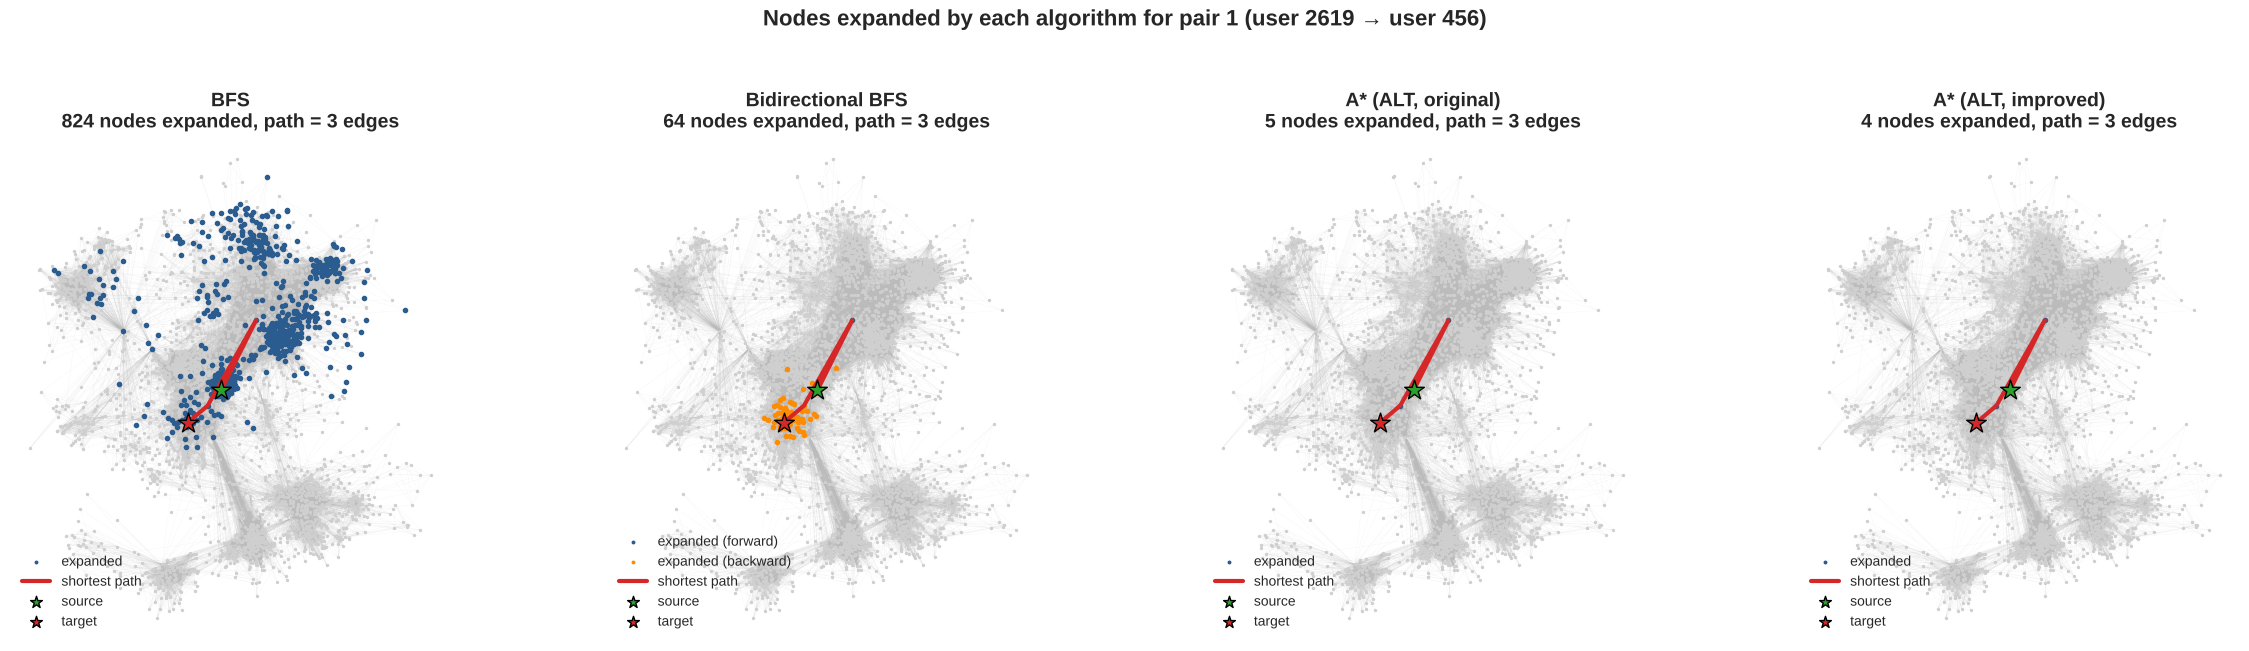

Saved to snap_facebook_results/explored_nodes_pair1.png


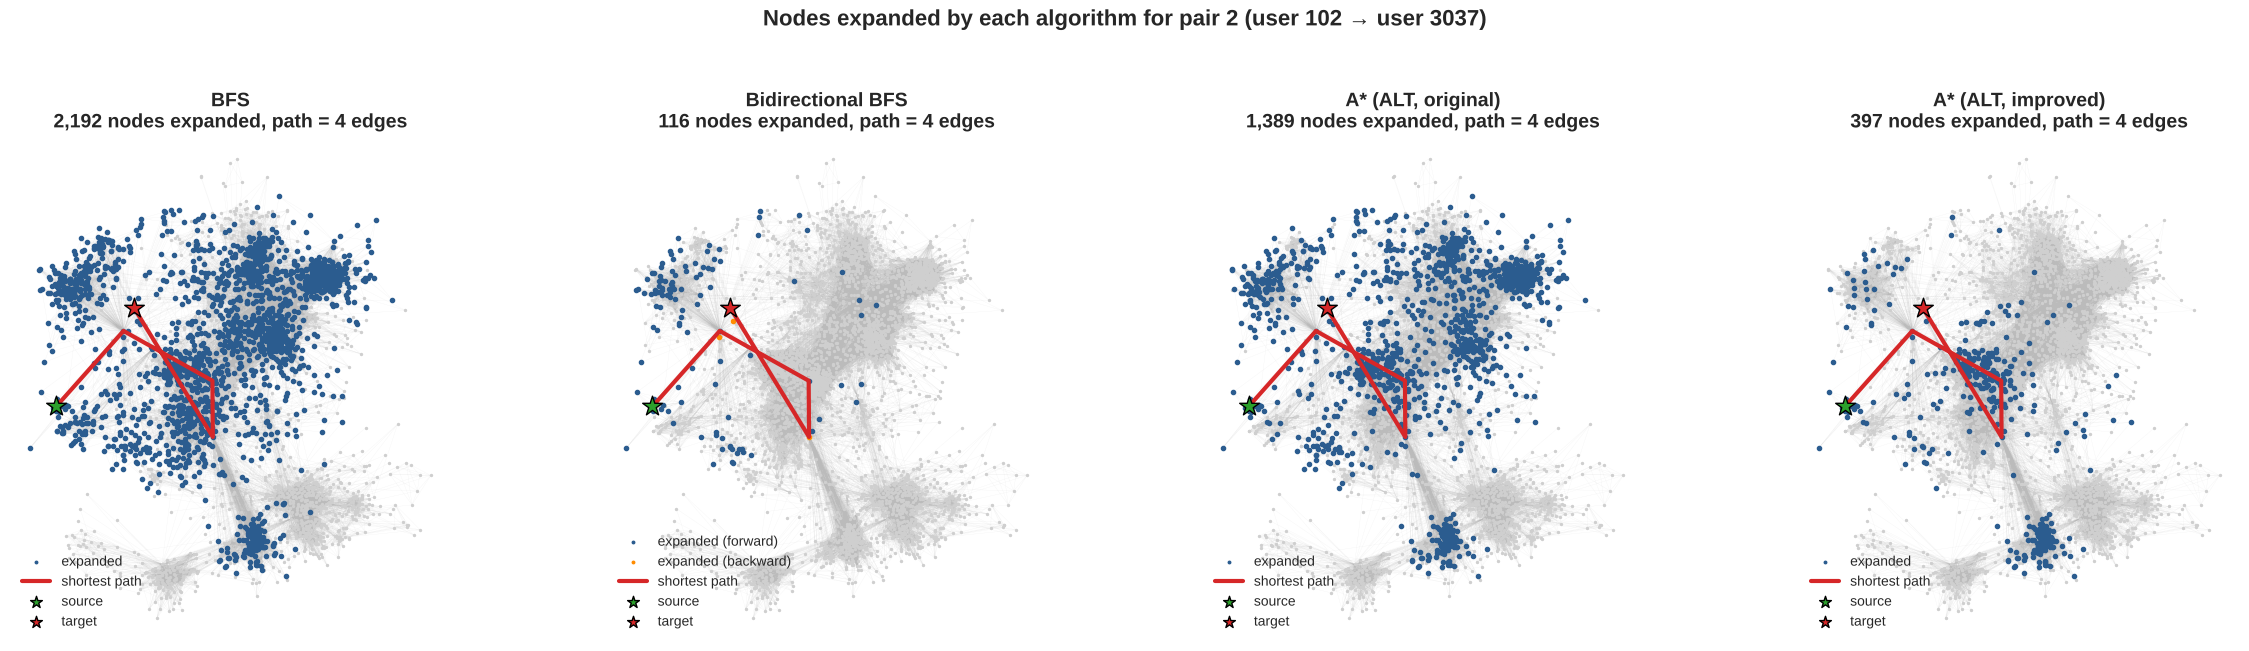

Saved to snap_facebook_results/explored_nodes_pair2.png


In [16]:
# ==============================================================================
# CELL 12: Explored-Nodes Visualization (search process of each algorithm)
# ==============================================================================
print("Computing full-graph layout (about 1 minute)...")
G_nx = nx.Graph()
G_nx.add_edges_from((u, v) for u in graph for v in graph[u] if u < v)
LAYOUT = nx.spring_layout(G_nx, seed=RANDOM_SEED, iterations=50)
xy_all = np.array([LAYOUT[n] for n in all_nodes])
edge_segments = [(LAYOUT[u], LAYOUT[v]) for u, v in G_nx.edges()]

def draw_explored(pair_index, out_path):
    src, tgt = test_pairs[pair_index]
    fig, axes = plt.subplots(1, 4, figsize=(24, 6.6))
    for ax, key in zip(axes, ALG_KEYS):
        trace = []
        path, p_len, p_exp, _, _ = ALGORITHMS[key][1](src, tgt, trace)
        ax.add_collection(LineCollection(edge_segments, colors="#bbbbbb", linewidths=0.15, alpha=0.25, zorder=0))
        ax.scatter(xy_all[:, 0], xy_all[:, 1], s=2, c="#cfcfcf", zorder=1)
        fwd = np.array([LAYOUT[n] for n, side in trace if side == "F"])
        bwd = np.array([LAYOUT[n] for n, side in trace if side == "B"])
        if len(fwd):
            ax.scatter(fwd[:, 0], fwd[:, 1], s=9, c="#2b5c8f", zorder=2,
                       label="expanded (forward)" if key == "bi" else "expanded")
        if len(bwd):
            ax.scatter(bwd[:, 0], bwd[:, 1], s=9, c="#ff8c00", zorder=2, label="expanded (backward)")
        pxy = np.array([LAYOUT[n] for n in path])
        ax.plot(pxy[:, 0], pxy[:, 1], color="#d62728", lw=3, zorder=3, label="shortest path")
        ax.scatter(*LAYOUT[src], s=220, c="#2ca02c", marker="*", edgecolors="black", zorder=4, label="source")
        ax.scatter(*LAYOUT[tgt], s=220, c="#d62728", marker="*", edgecolors="black", zorder=4, label="target")
        ax.set_title(f"{ALG_NAMES[key]}\n{p_exp:,} nodes expanded, path = {p_len} edges",
                     fontsize=14, fontweight="bold")
        ax.legend(loc="lower left", fontsize=10, framealpha=0.9, markerscale=0.6)
        ax.set_aspect("equal")
        ax.axis("off")
    fig.suptitle(f"Nodes expanded by each algorithm for pair {pair_index + 1} (user {src} \u2192 user {tgt})",
                 fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.9])
    plt.savefig(out_path, dpi=250)
    plt.show()
    print(f"Saved to {out_path}")

# Pair 1 is the sample pair used in the report; pair 2 is a typical 4-hop pair
for i in [0, 1]:
    draw_explored(i, os.path.join(OUTPUT_DIR, f"explored_nodes_pair{i + 1}.png"))

### Zoomed-in view of the search
The same layout as above, zoomed into the region around the shortest path. Expanded nodes are coloured by the **order** in which they were expanded (dark = early, light = late), and arrows show the direction of the path. When an algorithm expands only a few nodes (A* on pair 1), every expansion is numbered.

In [ ]:
# ==============================================================================
# CELL 12b: Zoomed-In View of the Search Process
# ==============================================================================
# Same layout as CELL 12, but each panel is zoomed into the region around the
# shortest path. Expanded nodes are coloured by the ORDER in which they were
# expanded (dark = early, light = late), so the growth of the search is visible.
# When an algorithm expands only a few nodes, each one is numbered.
import matplotlib
from matplotlib import cm
from matplotlib.colors import Normalize, LinearSegmentedColormap

def zoom_window(path, pad=0.35, min_half=0.10):
    pts = np.array([LAYOUT[n] for n in path])
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    centre = (lo + hi) / 2
    half = max((hi - lo).max() / 2 * (1 + pad), min_half)
    return centre, half

def draw_explored_zoom(pair_index, out_path, ncols=2, label_limit=30, fs=1.0):
    src, tgt = test_pairs[pair_index]
    ref_path = bfs_shortest_path(graph, src, tgt)[0]
    centre, half = zoom_window(ref_path)
    x0, x1, y0, y1 = centre[0] - half, centre[0] + half, centre[1] - half, centre[1] + half
    inside = lambda p: x0 <= p[0] <= x1 and y0 <= p[1] <= y1

    nrows = int(np.ceil(len(ALG_KEYS) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2 * ncols, 7.6 * nrows if nrows > 1 else 10.4))
    axes = np.atleast_1d(axes).ravel()
    cmap_f, cmap_b = matplotlib.colormaps["viridis"], matplotlib.colormaps["Oranges"]

    for ax, key in zip(axes, ALG_KEYS):
        trace = []
        path, p_len, p_exp, _, _ = ALGORITHMS[key][1](src, tgt, trace)
        ax.add_collection(LineCollection(edge_segments, colors="#9a9a9a", linewidths=0.35, alpha=0.18, zorder=0))
        ax.scatter(xy_all[:, 0], xy_all[:, 1], s=14, c="#d0d0d0", zorder=1)

        fwd = [(i, n) for i, (n, side) in enumerate(trace) if side == "F"]
        bwd = [(i, n) for i, (n, side) in enumerate(trace) if side == "B"]
        norm = Normalize(vmin=0, vmax=max(len(trace) - 1, 1))
        if fwd:
            pts = np.array([LAYOUT[n] for _, n in fwd])
            ax.scatter(pts[:, 0], pts[:, 1], s=46, c=[cmap_f(0.85 * norm(i)) for i, _ in fwd],
                       edgecolors="white", linewidths=0.3, zorder=2)
        if bwd:
            pts = np.array([LAYOUT[n] for _, n in bwd])
            ax.scatter(pts[:, 0], pts[:, 1], s=46, c=[cmap_b(0.35 + 0.65 * norm(i)) for i, _ in bwd],
                       edgecolors="white", linewidths=0.3, zorder=2)

        # Number every expansion when there are only a few of them
        if len(trace) <= label_limit:
            for order, (n, side) in enumerate(trace, start=1):
                x, y = LAYOUT[n]
                ax.annotate(str(order), (x, y), xytext=(13, 9), textcoords="offset points", fontsize=13 * fs,
                            fontweight="bold", color="#5a189a" if side == "F" else "#c2410c", zorder=6)

        pxy = np.array([LAYOUT[n] for n in path])
        ax.plot(pxy[:, 0], pxy[:, 1], color="#d62728", lw=3.5, zorder=3)
        for (xa, ya), (xb, yb) in zip(pxy[:-1], pxy[1:]):          # direction arrows, source -> target
            xm, ym = xa + 0.55 * (xb - xa), ya + 0.55 * (yb - ya)
            ax.annotate("", xy=(xm, ym), xytext=(xa + 0.45 * (xb - xa), ya + 0.45 * (yb - ya)),
                        arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=0, mutation_scale=26), zorder=4)
        for n in path:
            x, y = LAYOUT[n]
            ax.text(x, y - half * 0.055, str(n), ha="center", va="top", fontsize=11 * fs, fontweight="bold", zorder=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#d62728", lw=1))
        ax.scatter(*LAYOUT[src], s=420, c="#2ca02c", marker="*", edgecolors="black", zorder=5)
        ax.scatter(*LAYOUT[tgt], s=420, c="#d62728", marker="*", edgecolors="black", zorder=5)

        visible = sum(1 for n, _ in trace if inside(LAYOUT[n]))
        if ncols > 2:   # compact titles for the wide (poster) version
            detail = f" (forward {len(fwd)}, backward {len(bwd)})" if bwd else ""
            title = f"{ALG_NAMES[key]}\n{p_exp:,} nodes expanded{detail}"
        else:
            detail = f"forward {len(fwd)}, backward {len(bwd)}; " if bwd else ""
            title = f"{ALG_NAMES[key]}\n{p_exp:,} nodes expanded ({detail}{visible:,} inside this window)"
        ax.set_title(title,
                     fontsize=15 * fs, fontweight="bold")
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color("#888888")

    for ax in axes[len(ALG_KEYS):]:
        ax.axis("off")

    # Shared colour keys
    fig.subplots_adjust(left=0.02, right=0.98, top=0.90 if nrows > 1 else 0.84, bottom=0.10 if nrows > 1 else 0.20,
                        wspace=0.06, hspace=0.16)
    cax1 = fig.add_axes([0.14, 0.045 if nrows > 1 else 0.10, 0.32, 0.016 if nrows > 1 else 0.022])
    cb1 = fig.colorbar(cm.ScalarMappable(norm=Normalize(0, 1), cmap=LinearSegmentedColormap.from_list(
        "f", [cmap_f(v) for v in np.linspace(0, 0.85, 64)])), cax=cax1, orientation="horizontal")
    cb1.set_ticks([0, 1]); cb1.set_ticklabels(["expanded early", "expanded late"])
    cb1.set_label("Forward search (source side)", fontsize=12 * fs)
    cb1.ax.tick_params(labelsize=10 * fs)
    cax2 = fig.add_axes([0.56, 0.045 if nrows > 1 else 0.10, 0.32, 0.016 if nrows > 1 else 0.022])
    cb2 = fig.colorbar(cm.ScalarMappable(norm=Normalize(0, 1), cmap=LinearSegmentedColormap.from_list(
        "b", [cmap_b(v) for v in np.linspace(0.35, 1.0, 64)])), cax=cax2, orientation="horizontal")
    cb2.set_ticks([0, 1]); cb2.set_ticklabels(["expanded early", "expanded late"])
    cb2.set_label("Backward search (target side, Bidirectional BFS only)", fontsize=12 * fs)
    cb2.ax.tick_params(labelsize=10 * fs)

    fig.suptitle(f"Zoomed view of the search for pair {pair_index + 1} (user {src} → user {tgt}, "
                 f"path length {len(ref_path) - 1}). Grey = not expanded, red = shortest path",
                 fontsize=16 * fs, fontweight="bold")
    plt.savefig(out_path, dpi=200)
    plt.show()
    print(f"Saved to {out_path}")

for i in [0, 1]:
    draw_explored_zoom(i, os.path.join(OUTPUT_DIR, f"explored_zoom_pair{i + 1}.png"), ncols=2)
    draw_explored_zoom(i, os.path.join(OUTPUT_DIR, f"explored_zoom_pair{i + 1}_wide.png"), ncols=4, fs=1.35)

### BFS search tree for the sample pair
This figure shows the tree that BFS builds through its parent pointers, level by level, for pair 1. The path to the goal is highlighted. Only a few siblings are drawn at each level, and the remaining nodes at that depth are summarised in a box.

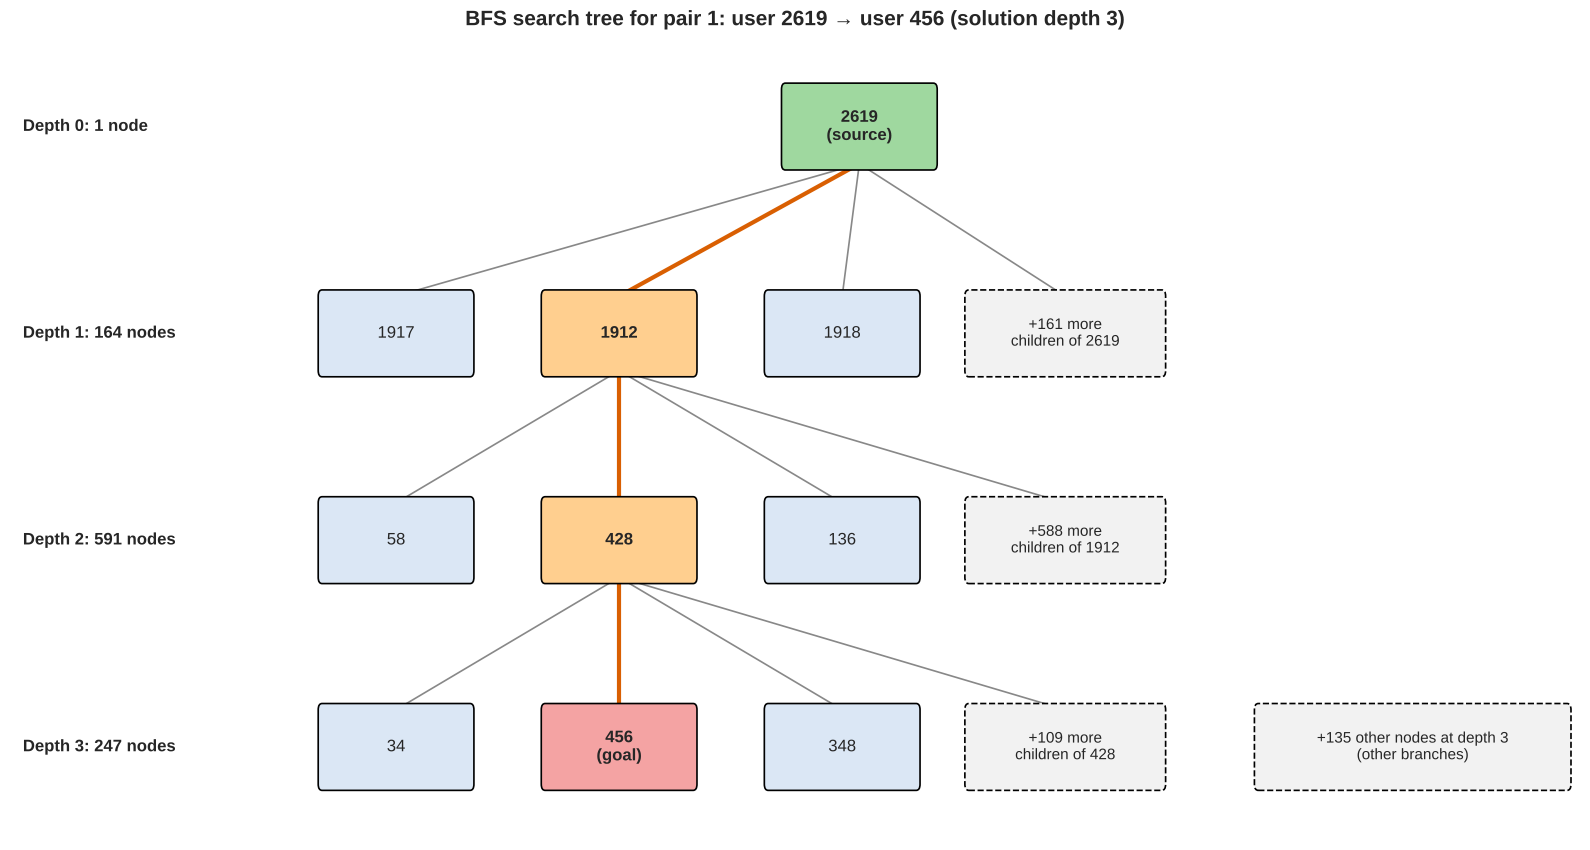

Saved to snap_facebook_results/bfs_search_tree_pair1.png
Nodes discovered per depth: {0: 1, 1: 164, 2: 591, 3: 247}


In [17]:
# ==============================================================================
# CELL 13: BFS Search Tree Diagram (sample pair)
# ==============================================================================
from matplotlib.patches import FancyBboxPatch

def draw_bfs_search_tree(adj_graph, source, target, out_path, siblings_shown=2):
    # Solution depth from BFS, then build the BFS tree (same neighbour order) down to that depth
    _, goal_depth, _, _, _ = bfs_shortest_path(adj_graph, source, target)
    parent, depth = {source: None}, {source: 0}
    q = deque([source])
    while q:
        u = q.popleft()
        if depth[u] >= goal_depth:
            continue
        for v in adj_graph[u]:
            if v not in parent:
                parent[v] = u
                depth[v] = depth[u] + 1
                q.append(v)
    path = []
    x = target
    while x is not None:
        path.append(x)
        x = parent[x]
    path.reverse()
    D = len(path) - 1
    level_size = {k: sum(1 for n in depth if depth[n] == k) for k in range(D + 1)}

    fig, ax = plt.subplots(figsize=(16, 2.0 * (D + 1) + 0.6))
    ax.set_xlim(-1.6, 10.6)
    ax.set_ylim(-D - 0.45, 0.45)
    ax.axis("off")

    def box(x, y, text, face, w=1.15, h=0.36, dashed=False, fs=12, bold=False):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03",
                                    facecolor=face, edgecolor="black", lw=1.2,
                                    linestyle="--" if dashed else "-", zorder=3))
        ax.text(x, y, text, ha="center", va="center", fontsize=fs,
                fontweight="bold" if bold else "normal", zorder=4)

    def edge(x1, y1, x2, y2, highlight=False):
        ax.plot([x1, x2], [y1 - 0.18, y2 + 0.18], color="#d95f02" if highlight else "#888888",
                lw=3 if highlight else 1.2, zorder=1)

    pos = {path[0]: (5.0, 0.0)}
    box(5.0, 0.0, f"{path[0]}\n(source)", "#9fd89f", bold=True)
    ax.text(-1.5, 0.0, "Depth 0: 1 node", ha="left", va="center", fontsize=12, fontweight="bold")

    for k in range(1, D + 1):
        par = path[k - 1]
        px, py = pos[par]
        children = [v for v in adj_graph[par] if parent.get(v) == par]
        on_path = path[k]
        sibs = [c for c in children if c != on_path][:siblings_shown]
        more = len(children) - 1 - len(sibs)
        others = level_size[k] - len(children)
        items = sibs[:1] + [on_path] + sibs[1:]
        xs = np.linspace(1.4, 6.6, len(items) + (1 if more > 0 else 0))
        y = -k
        for x_i, node in zip(xs, items):
            if node == on_path:
                face = "#f4a3a3" if k == D else "#ffcf8f"
                label = f"{node}\n(goal)" if k == D else f"{node}"
                box(x_i, y, label, face, bold=True)
                edge(px, py, x_i, y, highlight=True)
                pos[node] = (x_i, y)
            else:
                box(x_i, y, f"{node}", "#dbe7f5")
                edge(px, py, x_i, y)
        if more > 0:
            box(xs[-1], y, f"+{more} more\nchildren of {par}", "#f2f2f2", w=1.5, dashed=True, fs=11)
            edge(px, py, xs[-1], y)
        if others > 0:
            box(9.3, y, f"+{others:,} other nodes at depth {k}\n(other branches)", "#f2f2f2", w=2.4, dashed=True, fs=11)
        ax.text(-1.5, y, f"Depth {k}: {level_size[k]:,} nodes", ha="left", va="center", fontsize=12, fontweight="bold")

    ax.set_title(f"BFS search tree for pair 1: user {source} \u2192 user {target} (solution depth {D})",
                 fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved to {out_path}")
    return level_size

s0, t0 = test_pairs[0]
levels = draw_bfs_search_tree(graph, s0, t0, os.path.join(OUTPUT_DIR, "bfs_search_tree_pair1.png"))
print("Nodes discovered per depth:", levels)

In [18]:
# ==============================================================================
# CELL 12: Archive Generation and Colab File Downloads
# ==============================================================================
import shutil

zip_filename = "facebook_search_project_deliverables"
shutil.make_archive(zip_filename, "zip", OUTPUT_DIR)
print(f"All deliverables packaged into {zip_filename}.zip")

# Trigger automatic Colab download if running inside Google Colab
try:
    from google.colab import files
    print("Initiating automatic download via Google Colab API...")
    files.download(f"{zip_filename}.zip")
except ImportError:
    print(f"Local environment detected. Deliverables are saved in: ./{OUTPUT_DIR}/")

All deliverables packaged into facebook_search_project_deliverables.zip
Local environment detected. Deliverables are saved in: ./snap_facebook_results/
